# Adult Income Analysis 

**Question:** which factors are linked to earning more than 50K per year, and how strong are they?

**Dataset:** UCI Adult Census Income dataset (about 48,000 records from the 1994 US Census).

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, SciPy

**Method:** data quality check, cleaning, income rate by group (education, age, hours, workclass, gender, marital status), correlations, and statistical tests.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format

df = pd.read_csv(r'C:\Users\LENOVO\Desktop\Programmation\adult.csv', na_values='?', skipinitialspace=True)   # '?' means missing
df.shape

(48842, 15)

## 1. Data quality

In [4]:
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, 'missing_%': missing / len(df) * 100}).query('missing > 0')

,missing,missing_%
workclass,2799,5.73
occupation,2809,5.75
native-country,857,1.75


In [5]:
# Are rows with missing values different? Check before deleting them.
has_missing = df.isnull().any(axis=1)
check = df.groupby(has_missing)['income'].apply(lambda s: (s == '>50K').mean() * 100)
check.index = ['Complete rows', 'Rows with missing values']
print('Share earning >50K (%):'); print(check)
print('\nDuplicate rows:', df.duplicated().sum())

Share earning >50K (%):
Complete rows              24.78
Rows with missing values   13.23
Name: income, dtype: float64

Duplicate rows: 52


## 2. Clean the data

In [6]:
df = df.dropna().drop_duplicates().copy()
df['high_income'] = (df['income'] == '>50K').astype(int)     # 1 = earns more than 50K

# Helper columns for the analysis
df['age_group'] = pd.cut(df['age'], bins=[16, 25, 35, 45, 55, 65, 100],
                         labels=['17-25', '26-35', '36-45', '46-55', '56-65', '65+'])
df['hours_band'] = pd.cut(df['hours-per-week'], bins=[0, 30, 40, 50, 100],
                          labels=['30 or less', '31-40', '41-50', 'over 50'])
df['has_capital_gain'] = df['capital-gain'] > 0

print('Clean records:', len(df))
print(f"Overall share earning >50K: {df['high_income'].mean() * 100:.1f}%")

Clean records: 45175
Overall share earning >50K: 24.8%


## 3. Who is in the data?

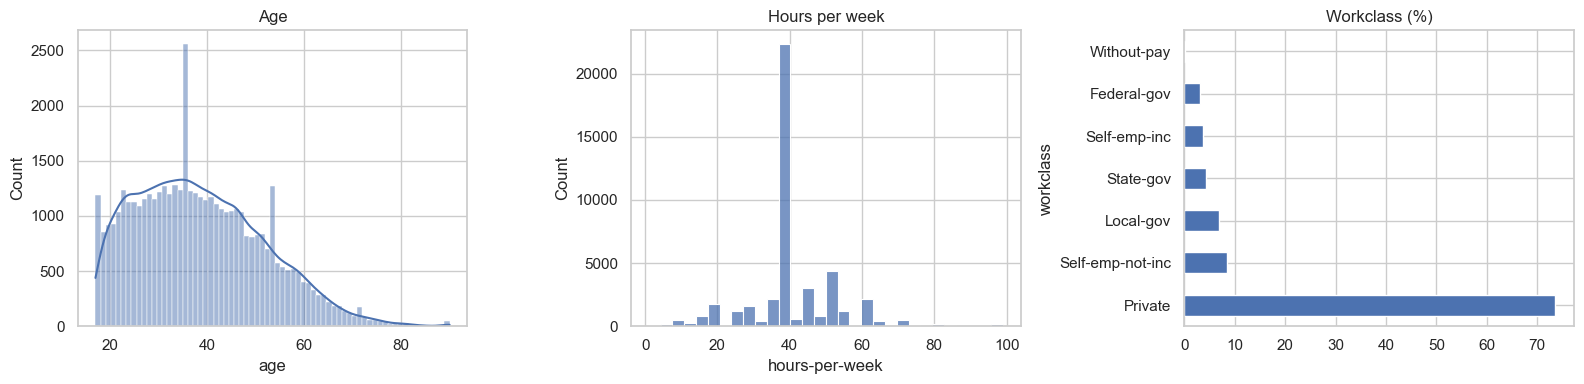

            age  hours-per-week
count 45,175.00       45,175.00
mean      38.56           40.94
std       13.22           12.01
min       17.00            1.00
25%       28.00           40.00
50%       37.00           40.00
75%       47.00           45.00
max       90.00           99.00


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['age'], kde=True, ax=ax[0]).set_title('Age')
sns.histplot(df['hours-per-week'], bins=30, ax=ax[1]).set_title('Hours per week')
df['workclass'].value_counts(normalize=True).mul(100).plot(kind='barh', ax=ax[2], title='Workclass (%)')
plt.tight_layout(); plt.show()
print(df[['age', 'hours-per-week']].describe())

## 4. Income rate by group

In [14]:
overall = df['high_income'].mean() * 100

def rate_by(col, min_n=100, order=None):
    g = df.groupby(col, observed=True)['high_income'].agg(['count', 'mean'])
    g['high_income_%'] = g['mean'] * 100
    g = g[g['count'] >= min_n].drop(columns='mean')
    if order is not None:
        return g.loc[[o for o in order if o in g.index]]   # skip groups with too few people
    return g.sort_values('high_income_%')

def plot_rate(g, title, figsize=(7, 4)):
    ax = g['high_income_%'].plot(kind='barh', figsize=figsize, title=title)
    ax.axvline(overall, color='red', ls='--', lw=1, label=f'overall {overall:.0f}%')
    ax.set_xlabel('% earning >50K'); ax.legend(); plt.tight_layout(); plt.show()

### Education

              count  high_income_%
education                         
1st-4th         220           3.64
5th-6th         447           4.92
7th-8th         822           6.69
9th             676           5.62
10th           1223           6.70
11th           1619           5.50
12th            575           7.48
HS-grad       14770          16.34
Some-college   9887          20.11
Assoc-voc      1958          25.74
Assoc-acdm     1507          26.41
Bachelors      7559          42.02
Masters        2513          55.43
Prof-school     785          75.41
Doctorate       544          73.35


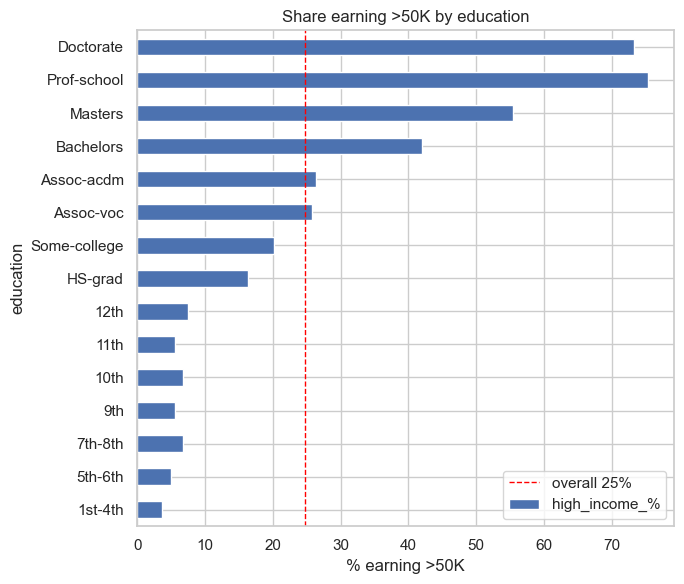

In [15]:
edu_order = df.groupby('education')['educational-num'].first().sort_values().index
g = rate_by('education', order=edu_order)
print(g); plot_rate(g, 'Share earning >50K by education', (7, 6))

### Age and hours worked

           count  high_income_%
age_group                      
17-25       8416           1.94
26-35      12067          19.14
36-45      11463          35.03
46-55       7931          39.67
56-65       3955          32.24
65+         1343          21.74


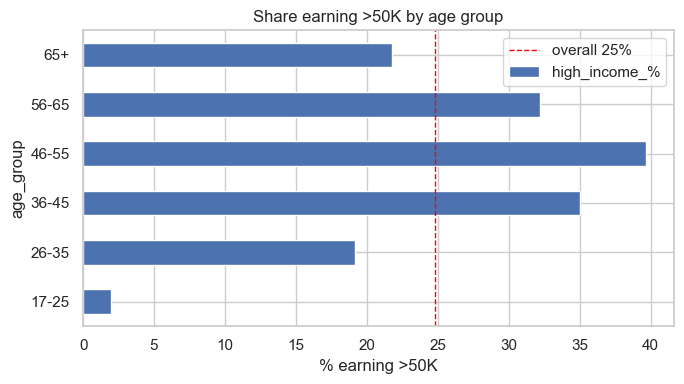

            count  high_income_%
hours_band                      
30 or less   6526           6.59
31-40       24880          20.92
41-50        8569          39.82
over 50      5200          41.44


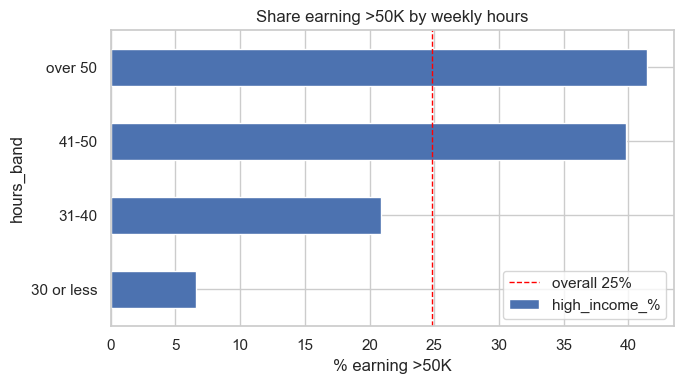

In [16]:
g = rate_by('age_group', order=['17-25', '26-35', '36-45', '46-55', '56-65', '65+'])
print(g); plot_rate(g, 'Share earning >50K by age group')
g = rate_by('hours_band', order=['30 or less', '31-40', '41-50', 'over 50'])
print(g); plot_rate(g, 'Share earning >50K by weekly hours')

### Workclass, occupation and marital status

                  count  high_income_%
workclass                             
Private           33262          21.78
State-gov          1946          26.72
Self-emp-not-inc   3795          27.91
Local-gov          3100          29.52
Federal-gov        1406          39.05
Self-emp-inc       1645          55.44


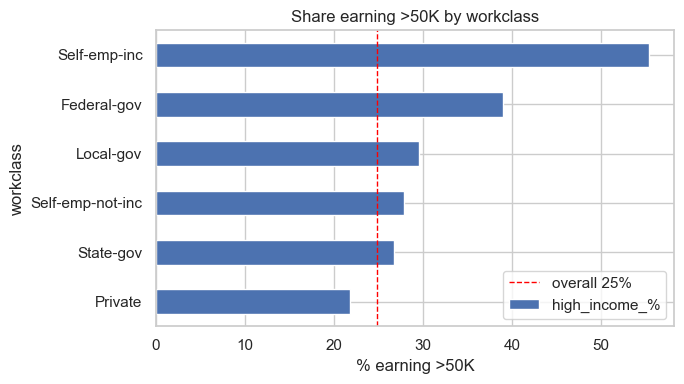

                   count  high_income_%
occupation                             
Priv-house-serv      230           1.30
Other-service       4805           4.08
Handlers-cleaners   2045           6.60
Farming-fishing     1475          11.66
Machine-op-inspct   2965          12.28
Adm-clerical        5535          13.66
Transport-moving    2316          20.64
Craft-repair        6010          22.53
Sales               5405          26.92
Tech-support        1419          28.96
Protective-serv      975          31.49
Prof-specialty      6001          45.03
Exec-managerial     5980          47.91


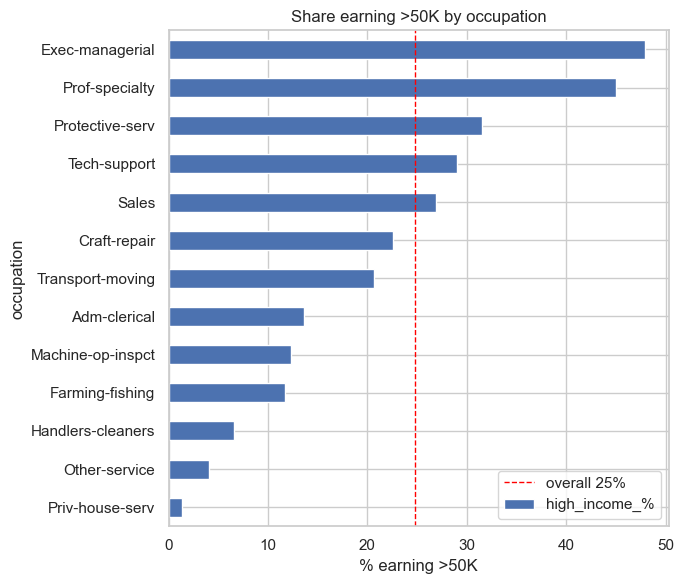

                       count  high_income_%
marital-status                             
Never-married          14567           4.81
Separated               1411           7.02
Widowed                 1277           9.48
Married-spouse-absent    552           9.78
Divorced                6294          10.41
Married-civ-spouse     21042          45.42


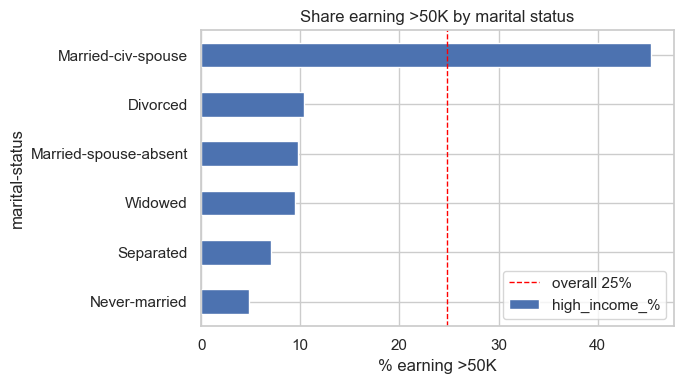

In [17]:
g = rate_by('workclass'); print(g); plot_rate(g, 'Share earning >50K by workclass')
g = rate_by('occupation'); print(g); plot_rate(g, 'Share earning >50K by occupation', (7, 6))
g = rate_by('marital-status'); print(g); plot_rate(g, 'Share earning >50K by marital status')

**Note:** the marital status gap is partly a household effect, so read it with care.

### Gender

        count  high_income_%
gender                      
Female  14680          11.37
Male    30495          31.26


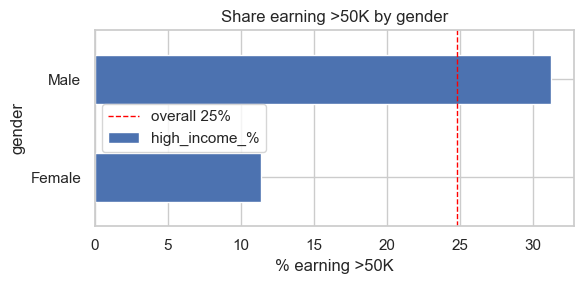


Share earning >50K by gender and weekly hours (%):
gender      Female  Male
hours_band              
30 or less    6.18  7.04
31-40        10.35 26.64
41-50        21.96 44.16
over 50      22.37 45.00


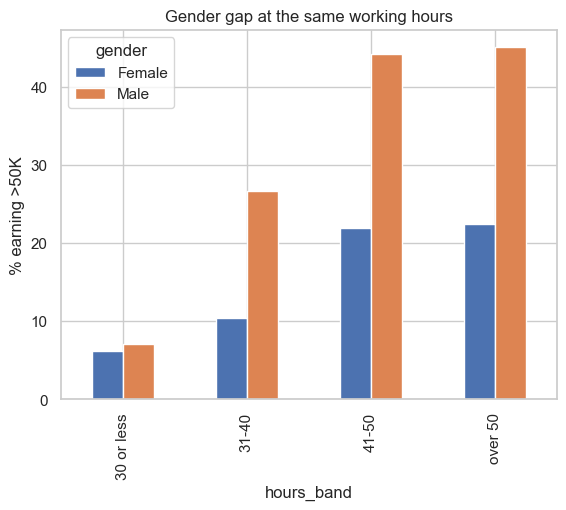

In [18]:
g = rate_by('gender'); print(g); plot_rate(g, 'Share earning >50K by gender', (6, 3))

# Does the gap remain at the same working hours?
tbl = df.pivot_table(index='hours_band', columns='gender', values='high_income', aggfunc='mean', observed=True) * 100
print('\nShare earning >50K by gender and weekly hours (%):'); print(tbl)
tbl.plot(kind='bar', title='Gender gap at the same working hours'); plt.ylabel('% earning >50K'); plt.show()

### Capital gains

In [19]:
g = rate_by('has_capital_gain', min_n=1); print(g)

                  count  high_income_%
has_capital_gain                      
False             41385          21.33
True               3790          62.66


## 5. Correlations

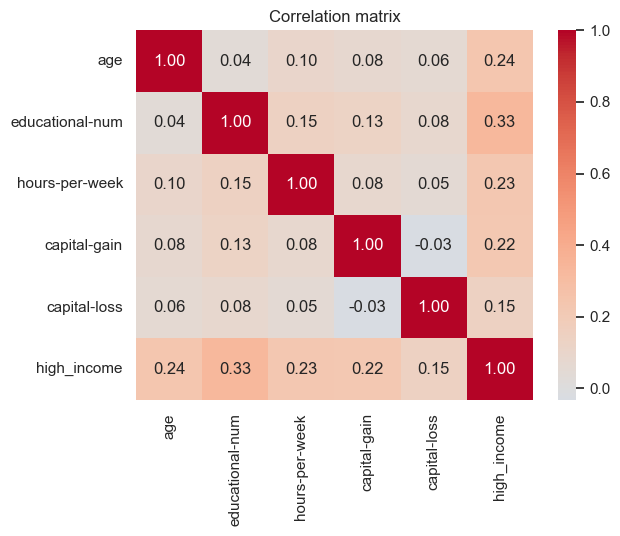

educational-num   0.33
age               0.24
hours-per-week    0.23
capital-gain      0.22
capital-loss      0.15
Name: high_income, dtype: float64


In [20]:
num = df[['age', 'educational-num', 'hours-per-week', 'capital-gain', 'capital-loss', 'high_income']]
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.show()
print(num.corr()['high_income'].drop('high_income').sort_values(ascending=False))

## 6. Are the differences real? (statistical tests)

In [21]:
for col in ['gender', 'marital-status', 'education', 'workclass']:
    table = pd.crosstab(df[col], df['high_income'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    print(f'{col:15s} p-value = {p:.4f} | Cramer V = {cramers_v:.2f}')

hi, lo = df.loc[df['high_income'] == 1, 'age'], df.loc[df['high_income'] == 0, 'age']
t, p = stats.ttest_ind(hi, lo, equal_var=False)
print(f'\nAverage age: >50K = {hi.mean():.1f}, <=50K = {lo.mean():.1f} (p = {p:.4f})')

gender          p-value = 0.0000 | Cramer V = 0.22
marital-status  p-value = 0.0000 | Cramer V = 0.45
education       p-value = 0.0000 | Cramer V = 0.36
workclass       p-value = 0.0000 | Cramer V = 0.16

Average age: >50K = 44.0, <=50K = 36.8 (p = 0.0000)


Cramer V shows how strong a link is: close to 0 is weak, closer to 1 is strong. A tiny p-value alone does not mean a big effect, because the dataset is large.


## Limitations
- The data comes from the 1994 US Census, so values and patterns may not match today.
- Income is only above or below 50K, with no exact salary.
- Links in the data are correlations, not proof of cause.
- The survey weights (`fnlwgt`) were not used.